# Pair-feature ablation

Compare seven particle-pair feature configurations using the saved experiment summary. The question is which feature groups are associated with the observed light-flavour gain.

The table contains recorded training, validation and evaluation metrics. This notebook reproduces its tabular comparisons and plots without retraining. Only the selected no-kaon predictions are included in full, so the other six rows are analysed as recorded summaries.

## Feature groups and comparison

The variants combine geometry, momentum, charge, explicit kaon-pair indicators and token type. All variants use the same six-class baseline for soft fusion. The no-kaon variant removes kaon information only from the pair-feature branch; it retains the token-level smeared kaon-ID input.

The summary stores accuracies and differences as fractions. Multiplication by 100 converts them to percentages or percentage points for display.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'scripts' / 'reproduce_results.py').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from within the repository.')
sys.path.insert(0, str(ROOT / 'scripts'))
from reproduce_results import (
    CLASS_NAMES, comparison_tables, load_results, plot_ablation, plot_comparison,
)

%matplotlib inline


In [2]:
summary = pd.read_csv(ROOT / 'results' / 'studies' / 'pairfeature_ablation_summary.csv')
assert len(summary) == 7
assert summary['pair_feature_set'].is_unique
columns = ['pair_feature_set', 'best_epoch', 'best_eval_loss', 'best_eval_acc',
           'standalone_uds_macro', 'soft_fused_macro', 'soft_delta_macro']
comparison = summary[columns].copy()
for column in ['best_eval_acc', 'standalone_uds_macro', 'soft_fused_macro', 'soft_delta_macro']:
    comparison[column] *= 100
comparison = comparison.rename(columns={
    'best_eval_acc': 'validation_accuracy_%',
    'standalone_uds_macro': 'uds_macro_%',
    'soft_fused_macro': 'fusion_macro_%',
    'soft_delta_macro': 'macro_delta_pp',
})
display(comparison.round(4))

,pair_feature_set,best_epoch,best_eval_loss,validation_accuracy_%,uds_macro_%,fusion_macro_%,macro_delta_pp
0,full,45,0.9550,50.8347,50.9511,62.5008,1.1478
1,geometry_only,49,0.9715,48.4621,48.6774,61.3928,0.0398
2,geometry_charge,47,0.9558,50.9417,50.8083,62.4379,1.0849
3,geometry_kaon,46,0.9724,48.4443,48.4797,61.3197,-0.0332
4,no_kaon,45,0.9553,51.0877,51.0196,62.5274,1.1745
5,no_charge,48,0.9712,48.8176,48.7690,61.4425,0.0896
6,geometry_momentum,45,0.9720,48.5880,48.7748,61.4926,0.1397


## Macro-accuracy gains

The horizontal axis reports the difference between each fused model and the shared six-class baseline on the saved evaluation sample.

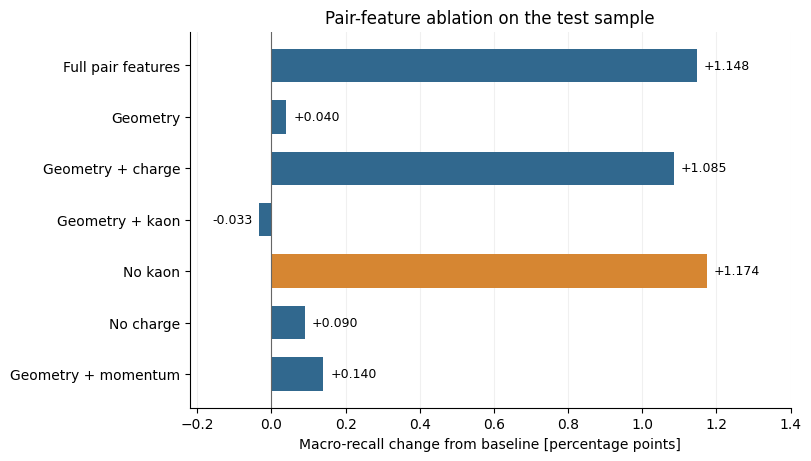

In [3]:
fig = plot_ablation(summary)
plt.show()

## Check the selected configuration against saved predictions

The full no-kaon prediction archive allows an independent recomputation of its recorded accuracy. The check below compares the recomputed overall and macro accuracies to the corresponding ablation row.

In [4]:
results = load_results(ROOT / 'results' / 'final')
accuracy, _ = comparison_tables(results)
selected = summary.set_index('pair_feature_set').loc['no_kaon']
np.testing.assert_allclose(
    [selected['soft_fused_overall'] * 100, selected['soft_fused_macro'] * 100],
    accuracy.loc[1, ['overall_%', 'macro_%']].to_numpy(dtype=float),
    rtol=0, atol=1e-10,
)
print('The no-kaon summary agrees with the saved predictions.')

The no-kaon summary agrees with the saved predictions.


## Interpretation and scope

Removing charge reduces the observed macro-accuracy gain from approximately +1.148 to +0.090 percentage points. Geometry plus charge retains most of the gain (+1.085 percentage points). Within these tested configurations, the result associates the gain primarily with charge-related pair information.

The no-kaon configuration has the highest recorded macro accuracy, but its advantage over the full pair-feature configuration is only about 0.027 percentage points. No repeated-seed or uncertainty study is provided, so this difference does not establish a robust advantage.

Checkpoints were selected by validation loss. All seven feature configurations were also compared on the same test sample used for the final comparison, so these results do not provide an independent test of feature-set selection.